### Q5: is overconfidence about the domain, or just about the model failing?
At 0 dB on ESC-10 every model is close to chance, so a huge ECE there may say nothing about the domain.
Here we do not compare models at the same SNR, but at the same accuracy: how overconfident is a model that is,
say, 40% accurate on ESC-10 against one that is 40% accurate on Speech Commands?

If the two datasets lie on one curve, the effect is "a failing model is overconfident" and not "domain mismatch".
If ESC-10 is clearly above, the domain hypothesis survives.

Only reads `results/results.csv`, no training.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
res = pd.read_csv('../results/results.csv')
NN = ['cnn', 'resnet', 'wav2vec']  # the random forest is underconfident and would hide the pattern
nn = res[res.model.isin(NN)]
COLORS = {'esc10': 'tab:red', 'sc': 'tab:blue', 'sc_small': 'tab:green'}
MARKERS = {'cnn': 'o', 'resnet': 's', 'wav2vec': '^'}

#### Overconfidence and ECE against accuracy

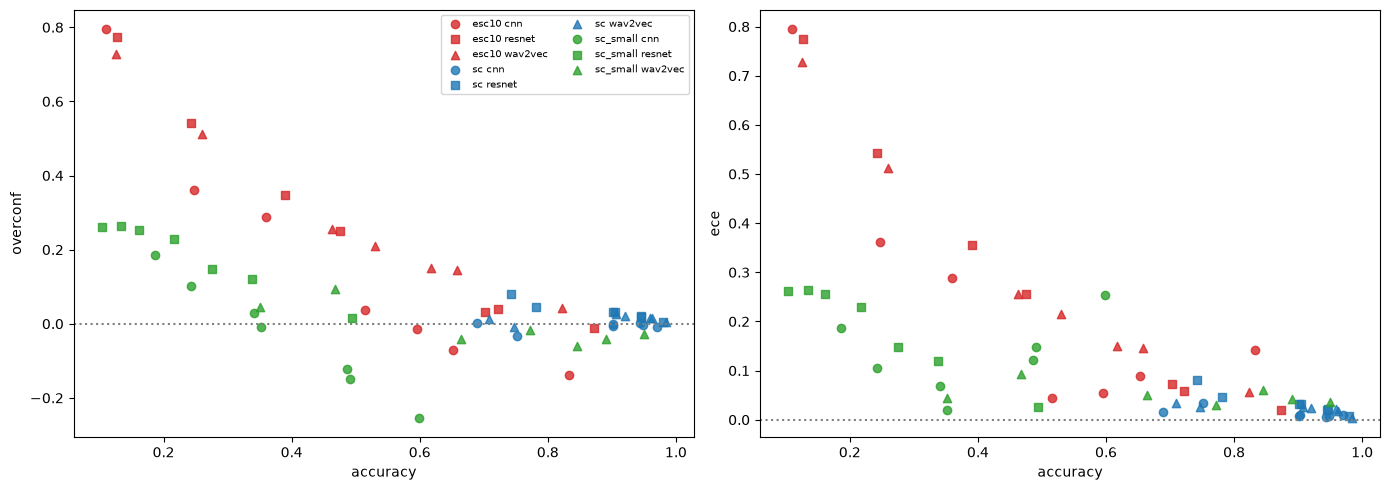

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric in zip(axes, ['overconf', 'ece']):
    for (dataset, model), part in nn.groupby(['dataset', 'model']):
        ax.scatter(part.acc, part[metric], c=COLORS[dataset], marker=MARKERS[model], alpha=0.8, label=f'{dataset} {model}')
    ax.axhline(0, color='gray', ls=':')
    ax.set_xlabel('accuracy'); ax.set_ylabel(metric)
axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout()
Path('../results/figures').mkdir(parents=True, exist_ok=True)
fig.savefig('../results/figures/q5_acc_vs_overconf.png', dpi=150, bbox_inches='tight')
plt.show()

#### Same accuracy, different dataset

In [3]:
edges = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
nn = nn.assign(accuracy_range=pd.cut(nn.acc, edges))
table = nn.pivot_table(index='accuracy_range', columns='dataset', values='overconf', aggfunc='mean', observed=False)
count = nn.pivot_table(index='accuracy_range', columns='dataset', values='overconf', aggfunc='count', observed=False)
print('mean (confidence - accuracy) in each accuracy range')
display(table.round(3))
print('number of points')
display(count)

mean (confidence - accuracy) in each accuracy range


dataset,esc10,sc,sc_small
accuracy_range,,,
"(0.0, 0.2]",0.766,NaN,0.242
"(0.2, 0.4]",0.411,NaN,0.095
"(0.4, 0.6]",0.148,NaN,-0.083
"(0.6, 0.8]",0.059,0.017,-0.029
"(0.8, 1.0]",-0.036,0.012,-0.043


number of points


dataset,esc10,sc,sc_small
accuracy_range,,,
"(0.0, 0.2]",3,0,4
"(0.2, 0.4]",5,0,7
"(0.4, 0.6]",5,0,5
"(0.6, 0.8]",5,6,2
"(0.8, 1.0]",3,15,3


Read each row left to right: same accuracy range, different dataset.
If the numbers in a row are close, the dataset does not matter once accuracy is fixed.
Rows with very few points (see the count table) should not be trusted.